# Beyond: the default definition is part of the PD, informative withdrawals and thin cohorts

**Question:** Can a bank take a PD from a rating agency's tables at face value: how far do the definition of default, the treatment of withdrawn ratings and the thinness of a grade move the number, and by how much more than the sampling error that the usual interval reports?

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 01, 02 and 07 of this topic (the PD by grade, the intervals and the IRB function)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- show on one agency's data that the definition of default is part of the PD: the same grade has two long-run PDs a factor of three apart under two pages of the same publication, and the portfolio risk weight moves with it;
- say how the sampling error of a PD compares with the effect of the definition;
- measure on rating paths of known truth how much informative withdrawals bias a PD under the three treatments in use, and why no matrix test sees it;
- measure exactly how often the interval of a thin grade contains its PD under three interval methods;
- state the claim BS-4 of the product, the evidence behind it and its limits.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.harness.performance import estimator_performance
from riskvalidation.regulatory import irb
from riskvalidation.transitions import estimators, intervals

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Three committed files of case C04 (ESMA CEREP, licence class `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: S&P's cohorts with their counts and withdrawals, the long-run PDs by grade under CEREP's pages (`outputs.lra`), their gap (`outputs.definition_gap`) and the IRB assumptions of the case.
- `data/derived/C04/withdrawals.json`: a simulation study on rating paths of known truth (the generator of notebook 03) in which a share of the ratings is withdrawn at 6% a year, and more often just before default by a factor $1 + k$ for $k$ in 0, 1, 3, 9 (informative withdrawals); 200 seeded datasets per rung. This notebook reruns that design with the engine, and reads from the file only the rejection rates of the two matrix tests, which need the harness's long simulations.
- `data/derived/C04/thin.json`: the generator's true PDs and the sizes of the thin-grade study; the coverage itself is computed here, exactly, by the engine.

**The three pages.** CEREP states that "no deterministic definition of a default event has been set up", so every PD names its page. `d2` is the default page: the distinct ratings counted as defaults over the page's own cohort. `d3` is its default events over the transition page's cohort. `d4` is the transition page's default column over the cohort less its withdrawals, the industry treatment.

In [2]:
# Load the three committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
sp = json.loads((C04 / "sp.json").read_text(encoding="utf-8"))
wd = json.loads((C04 / "withdrawals.json").read_text(encoding="utf-8"))
thin = json.loads((C04 / "thin.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades = out["grades"]

## Method

### Step 1: the definition is part of the PD

The long-run average default rate (EBA/GL/2017/16, paragraph 84) is the mean of the yearly rates over the cohorts where the grade has ratings, as in notebook 01. The next cell reads it for each grade under the default page (`d2`), the default events on the transition cohort (`d3`) and the transition page (`d4`). It then asks how large the sampling uncertainty of the `d4` number is, with two yardsticks: the engine's Jeffreys interval on the pooled counts of the CCC to C grade, and the standard error of the mean of its 26 yearly rates, a fairer yardstick for a long-run average because yearly rates move together with the credit cycle (Schuermann and Hanson, 2004, correct for this correlation with a design effect). Finally it measures the gap between the two pages against both.

In [3]:
# Long-run PD under the three pages, and the sampling uncertainty of the CCC to C rate of the transition page
lra = {d: np.array(out["lra"][d]["rate"], dtype=float) for d in ("d2", "d3", "d4")}
counts, at_risk = np.array(out["lra"]["d4"]["defaults"]), np.array(out["lra"]["d4"]["n"])
jeffreys = intervals.pd_jeffreys(counts, at_risk)
half = float(jeffreys["upper"][6] - jeffreys["lower"][6]) / 2
yearly = np.array([c["counts"][6][7] / (c["size"][6] - c["withdrawn"][6]) for c in out["cohorts"]])
cycle_se = yearly.std(ddof=1) / np.sqrt(len(yearly))
gap = lra["d2"][6] - lra["d4"][6]

print(f"CCC to C: d2 {lra['d2'][6]:.4f}, d3 {lra['d3'][6]:.4f}, d4 {lra['d4'][6]:.4f}")
print(f"d4 Jeffreys interval, pooled counts: {jeffreys['lower'][6]:.4f} to {jeffreys['upper'][6]:.4f}")
print(f"gap d2 minus d4 {gap:.4f} = {gap / half:.1f} half-widths of that interval")
print(f"gap in standard errors of the yearly mean {gap / cycle_se:.1f} ({cycle_se:.4f})")
ratio = lra["d4"][1:] / lra["d2"][1:]
print(f"d4 / d2 by grade, AA to CCC to C: {np.round(ratio, 3)}")

CCC to C: d2 0.2664, d3 0.2758, d4 0.0861
d4 Jeffreys interval, pooled counts: 0.0723 to 0.0897
gap d2 minus d4 0.1803 = 20.6 half-widths of that interval
gap in standard errors of the yearly mean 14.9 (0.0121)
d4 / d2 by grade, AA to CCC to C: [0.52  0.871 0.699 0.635 0.45  0.323]


What the definition does to capital follows. The next cell takes the grade mix of the 26 cohorts and the long-run PDs under `d2` and `d4`, and computes the average Basel III corporate risk weight with the engine's IRB function (maturity 2.5, PD floor 0.05%; the function is CRE31.5, the parameters CRE32, https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27), as in notebook 07. The LGD of 45% is the foundation-IRB value for senior unsecured claims on financial institutions (CRE32.6), combined with the non-financial corporate correlation and without the 1.25 multiplier of CRE31.7: the case's assumption, which sets the level of the weights and not the comparison, since the weight is proportional to the LGD.

In [4]:
# Average IRB risk weight of the cohort mix under d2 and d4
spec = out["irb"]
settings = {"lgd": spec["lgd"], "maturity": spec["maturity"], "regime": spec["regime"]}
mix = np.array([c["size"] for c in out["cohorts"]], dtype=float).sum(axis=0)
mix = mix / mix.sum()
portfolio = {}
for definition in ("d2", "d4"):
    results = [irb.capital_requirement(spec["asset_class"], float(p), **settings) for p in lra[definition]]
    portfolio[definition] = float(mix @ np.array([r.risk_weight for r in results]))
    print(f"{definition}: average risk weight {portfolio[definition]:.4f}")
print(f"change from d2 to d4 {portfolio['d4'] / portfolio['d2'] - 1:.3f}")

d2: average risk weight 0.5797
d4: average risk weight 0.4745
change from d2 to d4 -0.181


The figure draws the long-run PD of every grade under the three pages on the left, and the portfolio risk weight under the two definitions of the PD on the right.

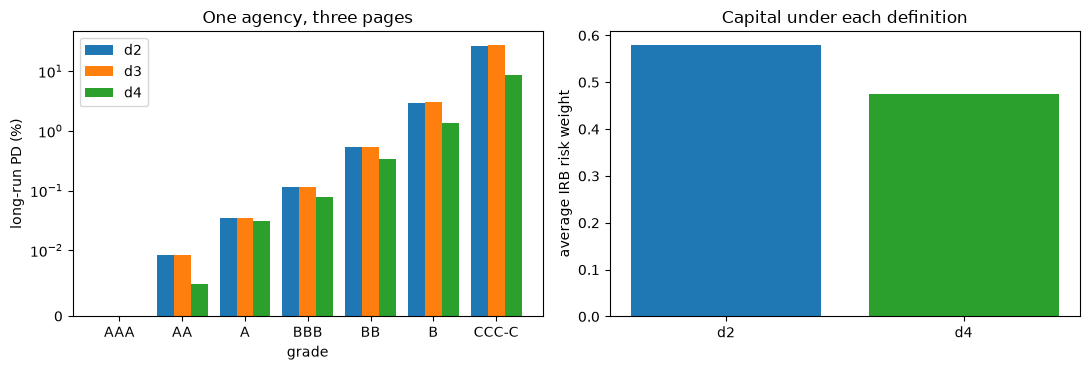

In [5]:
# Draw the long-run PD by page and the portfolio risk weight by definition
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
width = 0.27
for k, d in enumerate(("d2", "d3", "d4")):
    left.bar(np.arange(7) + (k - 1) * width, 100 * lra[d], width, label=d)
left.set_yscale("symlog", linthresh=0.01)
left.set_xticks(range(7))
left.set_xticklabels(grades)
left.set_xlabel("grade")
left.set_ylabel("long-run PD (%)")
left.set_title("One agency, three pages")
left.legend()
right.bar(["d2", "d4"], [portfolio["d2"], portfolio["d4"]], color=["tab:blue", "tab:green"])
right.set_ylabel("average IRB risk weight")
right.set_title("Capital under each definition")
fig.tight_layout()
plt.show()

The left panel shows the definition at work in every grade from AA down: the `d4` bars are shorter than the `d2` ones, by about a tenth for A, a third for BBB and a factor of three for CCC to C, while `d3`, the same defaults on the transition cohort, stays within a few per cent of `d2`. So the cohort and the treatment of withdrawals, and not the count of defaults, make the difference. The printed gap, 18.0 points for CCC to C, is 20.6 half-widths of the Jeffreys interval and 14.9 standard errors of the yearly mean: sampling, even allowing for the cycle, does not come near it. On the right the definition moves the portfolio's average risk weight by 18%. The figure does not say which page is right, only that the PD cannot be read without naming it.

### Step 2: informative withdrawals

A rating is withdrawn when the agency stops rating the borrower. The industry treatment (CEREP's transition page) treats a withdrawal as non-informative: it removes it and divides by what remains (Schuermann and Hanson, 2004, footnote 4). EBA/GL/2017/16, paragraph 76, asks instead to keep closed obligations and follow them. If borrowers in trouble are withdrawn more often, both are biased, and a validator cannot see it in the matrix. The design is the committed study's. Rating paths come from the generator of notebook 03 over five years of annual snapshots, 6% of the ratings are withdrawn each year, and a rating is withdrawn $1 + k$ times more often in the year before it defaults, for $k$ = 0 (non-informative), 1, 3 and 9. The same random stream draws the latent paths and the observed ones, so each dataset is paired. For each rung the next cell computes the one-year PD four ways: with withdrawals **removed**, **kept** unfollowed as an absorbing state, **followed** (each year's cohort as observed, with its end read on the latent path, so a rating withdrawn within the year that defaults by its end counts as a default), and from the **latent** chain (every obligor followed every year), which is the reference that sees everyone. It uses 200 datasets per rung and takes a few seconds.

In [6]:
# Draw paired latent and observed paths along the ladder and estimate the PD with four treatments of withdrawals
q_true = np.array(thin["outputs"]["generator"]["q"], dtype=float)
obligors = tuple(thin["outputs"]["generator"]["obligors"])
snapshots = tuple(float(t) for t in range(6))
latent_gen = RatingPaths(q_true, obligors, horizon=5.0, snapshots=snapshots)
truth = np.array(latent_gen.truth()["pd_by_grade"]["1"])
treatments = ("removed", "kept", "followed", "latent")
shown = {"removed": "removed", "kept": "kept", "followed": "followed"}
shown |= {"latent": "latent", "wald": "Wald", "agresti_coull": "Agresti-Coull", "jeffreys": "Jeffreys"}
ladder = (0, 1, 3, 9)
estimates = {}
for k in ladder:
    spec_k = {"withdrawal_rate": 0.06, "informative": k, "window": 1.0}
    gen = RatingPaths(q_true, obligors, horizon=5.0, snapshots=snapshots, **spec_k)
    estimates[k] = {name: np.zeros((200, 7)) for name in treatments}
    for i, child in enumerate(np.random.SeedSequence(7).spawn(200)):
        latent = latent_gen.draw(np.random.default_rng(child))
        seen = gen.draw(np.random.default_rng(child))
        tables, gone = [s["counts"] for s in seen["steps"]], [s["withdrawn"] for s in seen["steps"]]
        estimates[k]["removed"][i] = estimators.pooled_cohort(tables, gone)["matrix"][:7, 7]
        estimates[k]["kept"][i] = estimators.pooled_cohort(tables, gone, treatment="state")["matrix"][:7, 7]
        first, last = seen["snapshot_states"], latent["snapshot_states"]
        years = [gen.snapshot_counts(np.column_stack([first[:, t], last[:, t + 1]]))[0] for t in range(5)]
        estimates[k]["followed"][i] = estimators.pooled_cohort([s["counts"] for s in years])["matrix"][:7, 7]
        every = [s["counts"] for s in latent["steps"]]
        estimates[k]["latent"][i] = estimators.pooled_cohort(every)["matrix"][:7, 7]
print("true one-year PD of B and CCC to C:", np.round(truth[5:], 4))
print("datasets per rung:", estimates[0]["removed"].shape[0], "| rungs k:", ladder)

true one-year PD of B and CCC to C: [0.0117 0.0806]
datasets per rung: 200 | rungs k: (0, 1, 3, 9)


The next cell summarises each treatment with the engine's `estimator_performance`: the bias relative to the true PD and its Monte Carlo standard error, for B and for CCC to C at every rung.

In [7]:
# Relative bias of each treatment and its Monte Carlo error, from the engine's performance harness
bias, bias_se = {}, {}
for k in ladder:
    rows = {n: [estimator_performance(estimates[k][n][:, g], truth[g]) for g in (5, 6)] for n in treatments}
    bias[k] = {n: np.array([r["bias"] / truth[g] for r, g in zip(rows[n], (5, 6))]) for n in treatments}
    bias_se[k] = {n: np.array([r["bias_mcse"] / truth[g] for r, g in zip(rows[n], (5, 6))]) for n in treatments}
print(f"{'k':>4s}" + "".join(f"{shown[n]:>22s}" for n in treatments) + "   (B)")
for k in ladder:
    print(f"{k:4d}" + "".join(f"{bias[k][n][0]:+13.3f} ({bias_se[k][n][0]:.3f})" for n in treatments))
print(f"k = 9, CCC to C: " + ", ".join(f"{shown[n]} {bias[9][n][1]:+.3f}" for n in treatments))

   k               removed                  kept              followed                latent   (B)
   0       +0.022 (0.009)       -0.037 (0.009)       -0.004 (0.009)       -0.004 (0.008)
   1       -0.028 (0.009)       -0.085 (0.008)       -0.023 (0.009)       -0.004 (0.008)
   3       -0.127 (0.008)       -0.180 (0.008)       -0.061 (0.008)       -0.004 (0.008)
   9       -0.360 (0.008)       -0.400 (0.007)       -0.162 (0.008)       -0.004 (0.008)
k = 9, CCC to C: removed -0.338, kept -0.392, followed -0.185, latent +0.003


The figure draws the relative bias of the PD of B under each treatment along the ladder, with its Monte Carlo error as a bar, for the four values of $k$.

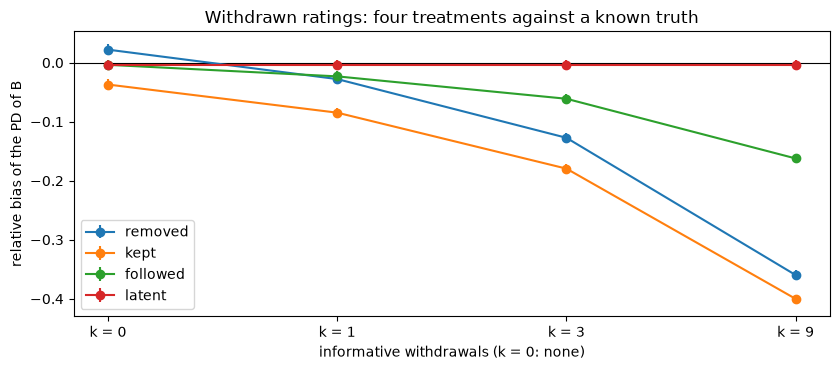

In [8]:
# Draw the relative bias of the PD of B under each treatment along the ladder
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for n in treatments:
    centre = [bias[k][n][0] for k in ladder]
    ax.errorbar(range(len(ladder)), centre, [bias_se[k][n][0] for k in ladder], marker="o", label=shown[n])
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set_xticks(range(len(ladder)))
ax.set_xticklabels([f"k = {k}" for k in ladder])
ax.set_xlabel("informative withdrawals (k = 0: none)")
ax.set_ylabel("relative bias of the PD of B")
ax.set_title("Withdrawn ratings: four treatments against a known truth")
ax.legend()
fig.tight_layout()
plt.show()

The latent chain, which sees everyone, stays on zero at every rung, so the generator and the estimator are sound. The three treatments of the observed paths leave it as $k$ grows. At $k = 0$ the removed and kept treatments already carry a small bias, upward for removing and downward for keeping, because keeping treats a withdrawal as an absorbing state that cannot default. At $k = 9$, the strongest rung, removing the withdrawn ratings understates the PD of B by 36%, keeping them by 40%, and following them as paragraph 76 asks still understates it by 16%. Following is the least biased of the three, and it is not unbiased. The bars are small next to these gaps, so the drift with $k$ is not Monte Carlo noise, but the figure says nothing about whether CEREP's withdrawals are informative: they are planted here.

The next question is whether the tests a validator has on the matrix would notice. The study's two matrix tests, time homogeneity across the five annual matrices and the last year's counts against the exact matrix, are Monte Carlo simulations of 200 datasets each in the harness, so their rejection rates at 5% are read from the committed file for each rung. A test with no power rejects about 5% of the datasets or fewer, whatever the bias.

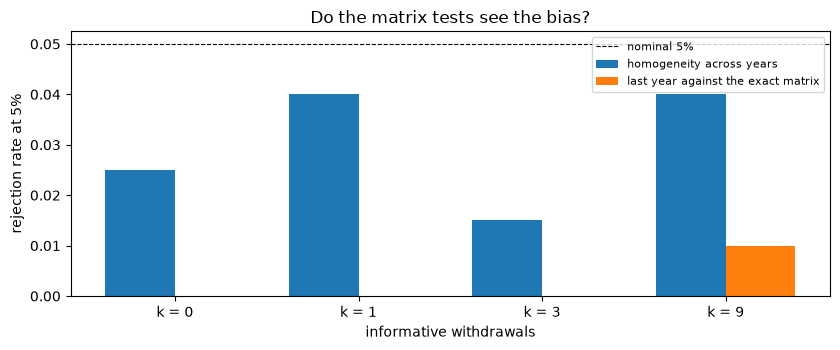

datasets per row: 200


In [9]:
# Draw the committed rejection rates at 5% of the two matrix tests along the ladder
sims = wd["outputs"]["simulations"]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
width = 0.38
tests_shown = (("rating.time_homogeneity", "homogeneity across years"),
               ("rating.matrix_reference", "last year against the exact matrix"))
for j, (test_id, label) in enumerate(tests_shown):
    rows = [next(s for s in sims if s["test_id"] == test_id and s["rung"] == k) for k in ladder]
    rates = [row["rates"]["p<0.05"]["rate"] for row in rows]
    ax.bar(np.arange(len(ladder)) + (j - 0.5) * width, rates, width, label=label)
ax.axhline(0.05, color="black", linestyle="--", linewidth=0.8, label="nominal 5%")
ax.set_xticks(range(len(ladder)))
ax.set_xticklabels([f"k = {k}" for k in ladder])
ax.set_xlabel("informative withdrawals")
ax.set_ylabel("rejection rate at 5%")
ax.set_title("Do the matrix tests see the bias?")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("datasets per row:", sims[0]["n_rep"])

Both tests reject at or below their nominal 5% at every rung, including $k = 9$, where the bias is a third of the PD: the matrix of the ratings that are still there passes as a Markov matrix, and the missing information is exactly what no test on it can see. The homogeneity test rejects a few per cent whatever $k$ is, and the last-year test almost never rejects. The figure says that these two tests cannot be the safeguard against informative withdrawals; it does not say that no test could, since a test that compared the withdrawn ratings with the survivors would need data the transition page does not publish.

### Step 3: thin grades

Notebook 02 showed that the Wald interval of a grade with no observed default has width zero. How often does each interval contain the true PD when the grade is thin? The coverage of an interval method for $n$ obligors with true PD $p$ is exact: add the binomial probability of every default count whose interval contains $p$. The engine's `exact_coverage` does it. The next cell computes it for the Wald, Agresti-Coull and Jeffreys intervals at the generator's true one-year PDs and the sizes of 50 to 1,000 obligors per grade that the study uses, and prints the coverage of the three best grades at the smallest and the largest size.

In [10]:
# Exact coverage of three intervals at the true PDs of the generator, by number of obligors per grade
sizes = [r["value"] for r in thin["outputs"]["rungs"]]
true_pd = np.array(thin["outputs"]["generator"]["pd_1y"])
coverage = {}
for method in ("wald", "agresti_coull", "jeffreys"):
    coverage[method] = np.array([intervals.exact_coverage(method, n, true_pd, level=0.95)["coverage"] for n in sizes])
print("true one-year PD of AAA, AA and A:", np.round(true_pd[:3], 5))
for method in coverage:
    for at in (0, -1):
        c = coverage[method][at]
        print(f"{shown[method]:14s} n = {sizes[at]:5d}: AAA {c[0]:.4f}, AA {c[1]:.4f}, A {c[2]:.4f}")
print("nominal level: 0.95")

true one-year PD of AAA, AA and A: [7.0e-05 5.0e-05 2.9e-04]
Wald           n =    50: AAA 0.0033, AA 0.0025, A 0.0143
Wald           n =  1000: AAA 0.0636, AA 0.0479, A 0.2506
Agresti-Coull  n =    50: AAA 1.0000, AA 1.0000, A 0.9999
Agresti-Coull  n =  1000: AAA 1.0000, AA 1.0000, A 0.9968
Jeffreys       n =    50: AAA 0.9967, AA 0.9975, A 0.9857
Jeffreys       n =  1000: AAA 0.9364, AA 0.9521, A 0.9656
nominal level: 0.95


The figure draws the exact coverage of the three intervals for AAA and for A against the number of obligors, with the nominal level as a dashed line.

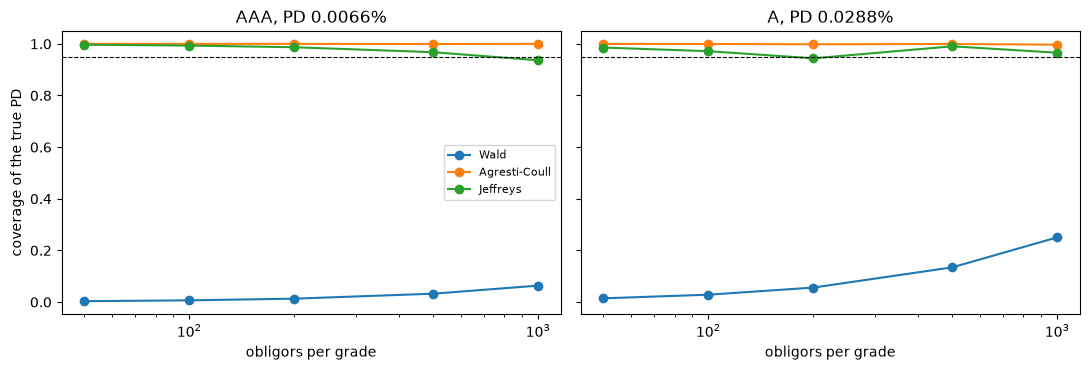

In [11]:
# Draw the exact coverage of the three intervals for AAA and A against the sample size
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, g in zip(axes, (0, 2)):
    for method in coverage:
        ax.plot(sizes, coverage[method][:, g], marker="o", label=shown[method])
    ax.axhline(0.95, color="black", linestyle="--", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xlabel("obligors per grade")
    ax.set_title(f"{grades[g]}, PD {100 * true_pd[g]:.4f}%")
axes[0].set_ylabel("coverage of the true PD")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

The Wald interval is far below the dashed line for AAA at every size: with 50 obligors it contains the true PD in 0.33% of the samples, because it contains it only when a default occurs, and the chance of one is the PD times 50. More obligors help slowly: for AAA it is still near 6% at 1,000, and for A, whose PD is four times larger, it rises from 1.4% to about a quarter. The Agresti-Coull interval over-covers at nearly 100% because it widens the interval around a rate of zero. The Jeffreys interval comes closest to the nominal level: for AAA it covers 99.7% at 50 obligors and 93.6% at 1,000. The figure is exact for this generator's PDs and sizes; it is a rating scale with these grade PDs, not every portfolio.

## State of the art

### The practice this goes beyond

- **The definition.** ESMA's CEREP publication states that no deterministic definition of a default event has been set up for it, and the cohort and duration estimators of the literature take the agencies' tables as given (Schuermann and Hanson, 2004; the research dossier 13, sections 4 and 5). A PD from a CEREP table is therefore read as a number, with its sampling error, and the definition behind it is not part of the estimate.
- **Withdrawals.** The industry removes them (Schuermann and Hanson, footnote 4), EBA paragraph 76 asks to keep and follow them; the practice discusses the choice and does not measure the bias of each against a truth.
- **Thin grades.** Schuermann and Hanson use the Wald and Agresti-Coull intervals for PDs by grade, with a design-effect correction for correlation; Brown, Cai and DasGupta (2001) study their coverage for a binomial proportion in general. The coverage of each at the PDs and sizes of a rating scale is the question the practice leaves.

The notebook measures each of the three on the same agency and on a generator of known truth.

## Beyond the state of the art

### Claim BS-4: the default definition as part of the PD, informative withdrawals and thin grades

**What Contraste adds.** The same agency's long-run PD of the CCC to C grade is 26.6% under the CEREP default page and 8.6% under the transition page, and the IRB risk weight of the cohort mix moves with the definition by a fifth; informative withdrawals and thin grades are measured on rating paths of known truth, with the engine, and the coverage of the usual intervals is computed exactly. The next cell lists each statement with the value that this notebook computed above, so the claim can be re-checked statement by statement.

In [12]:
# Each statement of the claim with the value this notebook computed
statements = [
    ("CCC to C long-run PD, default page (d2), %", 100 * lra["d2"][6]),
    ("CCC to C long-run PD, transition page (d4), %", 100 * lra["d4"][6]),
    ("IRB risk weight of the cohort mix under d2, %", 100 * portfolio["d2"]),
    ("IRB risk weight of the cohort mix under d4, %", 100 * portfolio["d4"]),
    ("B: relative bias, withdrawals removed, k = 9, %", 100 * bias[9]["removed"][0]),
    ("B: relative bias, withdrawals followed, k = 9, %", 100 * bias[9]["followed"][0]),
    ("AAA, 50 obligors: coverage of the Wald interval, %", 100 * coverage["wald"][0][0]),
    ("AAA, 50 obligors: coverage of the Jeffreys interval, %", 100 * coverage["jeffreys"][0][0]),
]
for text, value in statements:
    print(f"{value:9.3f}  {text}")

   26.637  CCC to C long-run PD, default page (d2), %
    8.608  CCC to C long-run PD, transition page (d4), %
   57.969  IRB risk weight of the cohort mix under d2, %
   47.454  IRB risk weight of the cohort mix under d4, %
  -35.974  B: relative bias, withdrawals removed, k = 9, %
  -16.226  B: relative bias, withdrawals followed, k = 9, %
    0.328  AAA, 50 obligors: coverage of the Wald interval, %
   99.672  AAA, 50 obligors: coverage of the Jeffreys interval, %


**Limits of the claim.** The definition gap is one agency's (S&P, EU entity, corporate long-term) and compares two pages of one publication that also count different cohorts (the artifact records the cohort difference as a finding); it says the definition matters, not which page is right. Informative withdrawals are planted in a simulation: the study shows what they would do and that no matrix test sees it, not that CEREP's withdrawals are informative. The thin-grade coverage is exact for the generator's PDs and sizes, a rating scale with these grade PDs. The claim is demonstrated by this notebook and the three files above, and is not stated beyond them.

The last figure puts the three parts of the claim side by side: the PD of CCC to C under the two pages with the `d4` interval, the bias of the PD of B under the three treatments at $k = 9$, and the coverage of the three intervals for AAA at 50 obligors.

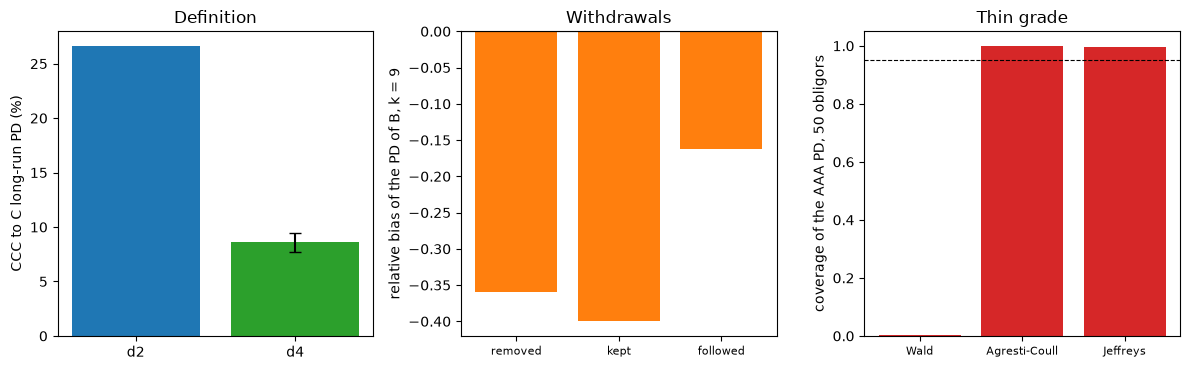

In [13]:
# Draw the three parts of the claim: the definition, the withdrawals and the thin grade
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
pages = ["d2", "d4"]
axes[0].bar(pages, [100 * lra[p][6] for p in pages], color=["tab:blue", "tab:green"])
axes[0].errorbar([1], [100 * lra["d4"][6]], [100 * half], color="black", capsize=4)
axes[0].set_ylabel("CCC to C long-run PD (%)")
axes[0].set_title("Definition")
axes[1].bar([shown[n] for n in treatments[:3]], [bias[9][n][0] for n in treatments[:3]], color="tab:orange")
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].set_ylabel("relative bias of the PD of B, k = 9")
axes[1].set_title("Withdrawals")
axes[2].bar([shown[m] for m in coverage], [coverage[m][0][0] for m in coverage], color="tab:red")
axes[2].axhline(0.95, color="black", linestyle="--", linewidth=0.8)
axes[2].set_ylabel("coverage of the AAA PD, 50 obligors")
axes[2].set_title("Thin grade")
for ax in axes[1:]:
    ax.tick_params(axis="x", labelsize=8)
fig.tight_layout()
plt.show()

Each panel is one statement of the claim at its headline size. On the left, the definition moves the CCC to C PD by two thirds, far outside the small black interval that a reader of one page would trust. In the middle, even the best treatment of withdrawals understates the PD of B at the strongest rung. On the right, the Wald interval almost never contains the PD of AAA at 50 obligors, the Agresti-Coull one nearly always does, and only the Jeffreys interval is near the dashed nominal level. The panels do not combine into one number: the three effects are measured on different data and do not add up to a total error of a PD.

## Results

**Answer:** No: the same agency's long-run PD of the CCC to C grade is 0.2664 under the default page and 0.0861 under the transition page, a gap of 0.1803 that is 20.6 half-widths of the Jeffreys interval of the second and 14.9 standard errors of its yearly mean, and it moves the average IRB risk weight of the cohort mix from 0.5797 to 0.4745, 0.181 lower. Informative withdrawals at `k = 9` understate the PD of B by 0.360 when removed, 0.400 when kept and 0.162 when followed, and neither matrix test rejects more than its nominal level. In a thin grade the Wald interval contains the true PD of AAA in 0.0033 of the samples at 50 obligors and in 0.0636 at 1,000, against 0.9967 and 0.9364 for the Jeffreys interval.

- **The definition is part of the PD.** Under the default page the long-run PD of CCC to C is 26.64% and under the transition page 8.61%, a ratio of 0.323 (the committed gap, pooled over the cohorts where both pages exist, is 0.294); for B the ratio is 0.450. The default events on the transition cohort (`d3`) are within 5% of the default page. The Jeffreys interval of the `d4` rate on the pooled counts runs from 0.0723 to 0.0897, and the standard error of the mean of its 26 yearly rates is 0.0121: sampling, even with the yearly rates' correlation with the cycle, does not come near the definition.
- **It moves capital.** The average Basel III corporate risk weight of the cohort mix is 57.97% with the default-page PDs and 47.45% with the transition-page PDs, 18.1% lower.
- **Informative withdrawals.** At `k = 0` removed and kept are already off by +0.022 and -0.037 for B, and the bias grows with `k`: at `k = 9` the three treatments understate the PD of B by 0.360, 0.400 and 0.162 and that of CCC to C by 0.338, 0.392 and 0.185, with a Monte Carlo error of about 0.008 on B, while the latent chain sits on -0.004. The rejection rates of the two matrix tests at 5% stay within their nominal level at every rung, so no matrix test sees the bias.
- **Thin grades.** With 50 obligors per grade the Wald interval contains the true PD of AAA in 0.33% of the samples (AA 0.25%, A 1.43%) and in only 6.36% with 1,000 obligors (AA 4.79%, A 25.06%); the Agresti-Coull interval contains it in at least 99.99% of the samples for AAA and AA and the Jeffreys interval in 99.67% at 50 obligors and 93.64% at 1,000 (nominal 95%).
- **The claim.** The eight statements of the claim BS-4 are listed with the values this notebook computed.

What this notebook does not show: that the withdrawals of CEREP are informative (they are planted in the simulation), or which page of CEREP is the right definition (the claim is that the choice matters and is not in the estimate).

## Summary

- The same agency's long-run PD of the CCC to C grade is 26.6% or 8.6% according to the page of CEREP it is read from, and the risk weight of the cohort mix moves a fifth; the definition is part of the PD and not in its confidence interval.
- Informative withdrawals understate a PD by a third when removed and by about a sixth when followed, and no matrix test sees it.
- The Wald interval of a thin grade almost never contains its PD; the Jeffreys interval does, and the Agresti-Coull one over-covers.
- The claim BS-4 is stated only as far as these committed files and this notebook go.

**What to try next.** Rerun the ladder of Step 2 for another grade and look at where the three treatments diverge; then read notebook 11 on the reconciliations.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions, with its help file ESMA65-8-10634 (sections 4.2 to 4.4 on the pages and the statement on the definition of default). https://registers.esma.europa.eu/cerep-publication/
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, footnote 4 (withdrawals) and section 3 (intervals). https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- BCBS, Basel Framework, CRE32, IRB approach: risk-weighted asset calculation. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- EBA (2017), Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures, EBA/GL/2017/16, paragraphs 73, 76, 84 and 86.